# DECANT + PCA on the Mouse Brain scATAC dataset

DECANT feature selection followed by a PCA embedding on the Mouse Brain scATAC dataset, then evaluation with the six integration metrics and the Overall score.

Download the dataset from [Google Drive](https://drive.google.com/drive/folders/1gQBjm_2TH0Ozjg_jO_7rwSgeKNp8emVh?usp=sharing) and point `DATA_PATH` at it.

## Setup

In [1]:
import numpy as np
import scipy.sparse as sp
import scanpy as sc
import pandas as pd
import episcanpy.api as epi
from decant.core import run_decant
from decant.preprocess import tfidf_for_visualization
from decant.metrics import evaluate_metrics, calc_overall

DATA_PATH = "../data/mouse_brain.h5ad"   # edit to point at your file
OMICS = "atac"
BATCH_KEY = "batch"
LABEL_KEY = "cell_type"
FPEAK_POOL, FPEAK_STRICT, MAX_FEATURES = 0.01, 0.03, 30000
SEED = 0


## Data preprocessing

Binarize the peak matrix, then keep peaks detected in enough cells (episcanpy). The candidate pool is peaks in >= 1% of cells; the number DECANT selects is capped by the >= 3% peak set and by MAX_FEATURES.

In [2]:
adata = sc.read_h5ad(DATA_PATH)
epi.pp.binarize(adata)
n_cells = adata.shape[0]
strict = adata.copy()
epi.pp.filter_features(strict, min_cells=int(np.ceil(FPEAK_STRICT * n_cells)))
n_strict = strict.shape[1]
epi.pp.filter_features(adata, min_cells=int(np.ceil(FPEAK_POOL * n_cells)))
N_FEATURES = min(n_strict, MAX_FEATURES)
print("strict peaks:", n_strict, "| pool:", adata.shape[1], "| selecting:", N_FEATURES)


strict peaks: 42368 | pool: 162398 | selecting: 30000


## Visualize before DECANT (all features)

UMAP of a TF-IDF then PCA embedding built from all preprocessed peaks, before DECANT selects any. Colour by batch and cell type, then compare with the after-DECANT UMAP.

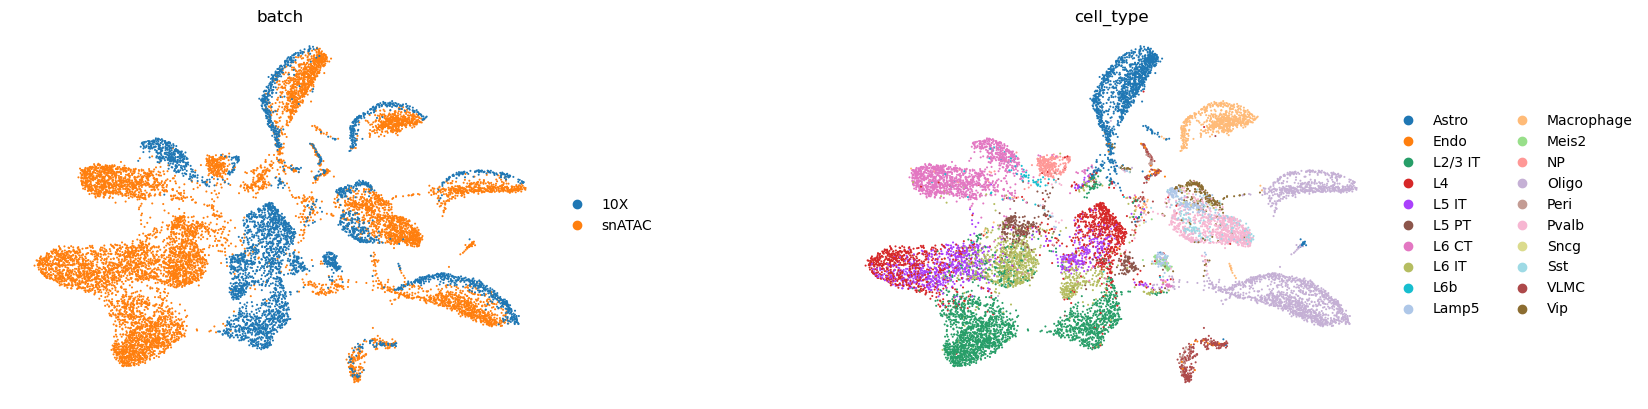

In [3]:
before = adata.copy()
before.X = tfidf_for_visualization(before.X)
sc.tl.pca(before, n_comps=50, random_state=SEED)
sc.pp.neighbors(before, use_rep="X_pca", n_neighbors=15, random_state=SEED)
sc.tl.umap(before, random_state=SEED)
sc.pl.umap(before, color=[BATCH_KEY, LABEL_KEY], wspace=0.4, frameon=False)

## DECANT feature selection

DECANT is label-free: it ranks features and selects the gamma with the highest tuning score.

In [4]:
result = run_decant(adata, omics=OMICS, batch_key=BATCH_KEY,
                    n_features=N_FEATURES, seed=SEED)
print(f"Selected {result['n_features']} features")


Selected 30000 features


The DECANT process is expected to take approximately 10-20 minutes.

## Evaluate integration

This step is downstream of feature selection: it benchmarks the DECANT embedding with the six integration metrics and the Overall score.

In [5]:
metrics = evaluate_metrics(result["embedding"], "X_pca", BATCH_KEY, LABEL_KEY)
metrics["Overall"] = calc_overall(metrics, result["n_batches"])
pd.Series(metrics).round(4)


AMI                   0.6769
ARI                   0.4400
NMI                   0.6791
batchASW              0.5772
Graph_connectivity    0.8487
iLISI                 1.2322
Overall               0.5803
dtype: float64

## Visualize after DECANT (selected features)

UMAP of a TF-IDF then PCA embedding on the DECANT-selected peaks. Same pipeline as the before-DECANT UMAP above, only the feature set differs.

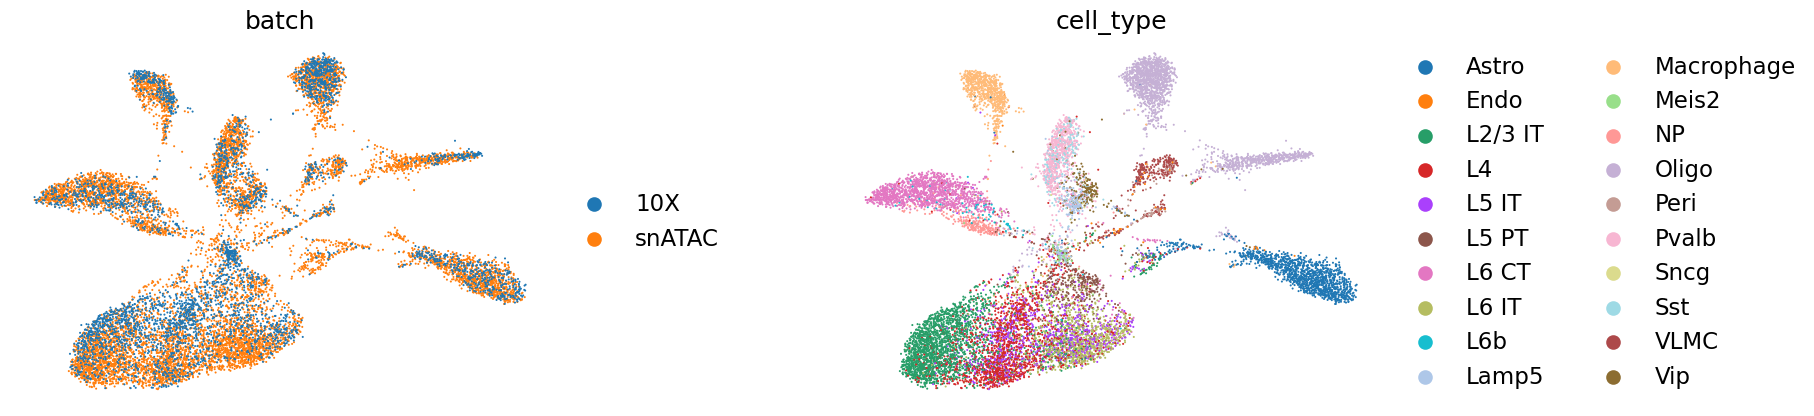

In [6]:
emb = adata[:, result["selected_indices"]].copy()
emb.X = tfidf_for_visualization(emb.X)
sc.tl.pca(emb, n_comps=50, random_state=SEED)
sc.pp.neighbors(emb, use_rep="X_pca", n_neighbors=15, random_state=SEED)
sc.tl.umap(emb, random_state=SEED)
sc.pl.umap(emb, color=[BATCH_KEY, LABEL_KEY], wspace=0.4, frameon=False)